# Analisis Persona Gender pada ETHICS — Keseluruhan dan Empat Subset

Notebook ini menampilkan hasil keseluruhan ETHICS serta rincian Commonsense,
Deontology, Justice, dan Virtue. Seluruh 81.756 respons dari enam model dan
sembilan persona pada bundle sumber digunakan tanpa sampling tambahan.

- Bagian utama tanpa pemisahan subset: distribusi wrong/acceptable/abstain/missing
  gabungan empat subset, delta terhadap netral, dan delta implicit–explicit.
- Keseluruhan: status, coverage, dan alasan abstain untuk empat subset.
- Commonsense/Justice: akurasi per subset, bersama commit_rate.
- Deontology/Virtue: distribusi wrong/acceptable, bersama commit_rate.

Figure utama dibaca langsung dari `figures/`. Bar chart detail
empat subset dibaca dari `per_subset/`. Semua ditampilkan langsung di notebook ini.

## Konsistensi tampilan

Palet persona mengikuti referensi GSM8K Regional: biru, teal, merah, oranye,
hijau tua, hijau muda, ungu, magenta; Neutral abu-abu. Gender menggunakan empat
warna pertama dan abu-abu karena hanya memiliki dua identitas.
Grafik akurasi memakai 3 desimal, anotasi 20 pt,
dan sumbu Y 0–1. Angka lengkap tetap berada di tabel.

Heatmap Regional memakai empat panel dengan 14/14/12/12 perbandingan, masing-masing
menjaga seluruh skenario satu persona atau pasangan tetap bersama. File `07` dan
`09` dengan akhiran `part1` kini berisi **seluruh p-value Exact McNemar**;
`part2` berisi **seluruh p-value Holm**. File `06` dan `08` tetap ukuran efek.
Nama file dipertahankan supaya tautan lama tidak terputus.

Heatmap utama Gender memakai tiga panel: Man (7 perbandingan), Woman (7),
dan Man–Woman (4). P-value mentah dan Holm disajikan terpisah; file `09` lama
menampilkan p-value mentah dan `09_ethics_gender_combined_holm_pvalue_heatmap`
menampilkan Holm. Angka efek menggunakan palet biru–netral–merah yang sama.

Konvensi tanda signifikan tidak diubah: pada Regional, bintang p-value mentah
berarti p mentah < 0,05; pada efek dan Holm berarti p Holm < 0,05. Religion tetap
memakai keputusan Holm pada ketiga heatmap. Warna efek biru–netral–merah berpusat
di nol, dengan rentang simetris yang disesuaikan terhadap data masing-masing grafik.
Jangan membandingkan besar efek hanya dari intensitas warna antargrafik.

Cakupan tidak berubah: akurasi Regional dan Gender memakai Commonsense + Justice;
Religion memakai kecocokan label empat subset pada committed, dengan coverage.
Delta Regional adalah delta akurasi; delta Religion dan Gender adalah delta stance wrong.


## 1. SPEC

Tujuan: menyajikan versi keseluruhan dan versi per subset dalam notebook yang
sama. Kriteria selesai: empat subset tampil pada tabel dan figure, akurasi
disertai coverage, hash artefak cocok, dan semua sel berhasil dijalankan.

Sumber dan hasil parsing tetap digunakan apa adanya. Tidak ada API call,
parsing ulang, atau rescoring. Deontology memiliki masalah excuse yang tidak
terkirim; prompt Virtue tidak sesuai tugas kecocokan sifat. Keterbatasan tersebut
mengikuti `docs/plan_parsing_ethics.md`. Stance keduanya menggambarkan jawaban
terhadap prompt eksperimen.

## 2. DESIGN PLAN

- Baca tabel sumber dan bundle revisi yang sudah ada.
- Periksa cakupan model, persona, subset, denominator, dan hash artefak.
- Tampilkan status keseluruhan serta akurasi/stance per subset bersama coverage.
- Tampilkan 3 chart gabungan, 13 chart pendukung, dan 8 bar chart detail.
- Seluruh teks pada figure selain judul diperbesar 2 pt dari ukuran renderer asal.
- Sajikan efek berpasangan, effect size, dan koreksi Holm dari sumber.

Tabel mempertahankan masing-masing persona I1, I2, dan I3. Bar chart detail
merangkum ketiganya dalam kategori implicit mengikuti generator yang tersedia.

## 3. IMPLEMENTATION — Baca sumber dan bundle revisi

In [1]:
import hashlib
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

def find_root():
    for path in [Path.cwd(), *Path.cwd().parents]:
        if (path / "result/ETHICS").is_dir() and (path / "notebooks").is_dir():
            return path
    raise FileNotFoundError("Root repositori tidak ditemukan")

def sha256_file(path):
    with path.open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()

ROOT = find_root()
NOTEBOOK_DIR = ROOT / "notebooks/gender/ethics accuracy analysis"
REVISION_DIR = NOTEBOOK_DIR
FIGURE_DIR = REVISION_DIR / "figures"
TABLE_DIR = REVISION_DIR / "tables"
CHILD_DIR = NOTEBOOK_DIR / "per_subset"
SOURCE = ROOT / "result/ETHICS/reports/Gender_Persona/_combined/persona_publication_analysis_v2_readable_paired_holm_six_models"
manifest = json.loads((REVISION_DIR / "bundle_manifest.json").read_text(encoding="utf-8"))
source_manifest_path = SOURCE / "metadata/analysis_manifest.json"
source_manifest = json.loads(source_manifest_path.read_text(encoding="utf-8"))
condition_summary = pd.read_csv(SOURCE / "tables/condition_summary_full.csv")
independence = pd.read_csv(SOURCE / "tables/persona_status_independence.csv")
status = pd.read_csv(TABLE_DIR / "status_by_model_persona.csv")
accuracy = pd.read_csv(TABLE_DIR / "accuracy_construct_valid_subsets.csv")
stance = pd.read_csv(TABLE_DIR / "stance_construct_invalid_subsets.csv")
reasons = pd.read_csv(TABLE_DIR / "abstain_reason_by_model_persona.csv")
paired = pd.read_csv(TABLE_DIR / "paired_primary_effects_vs_neutral.csv")
combined = pd.read_csv(TABLE_DIR / "ethics_combined_four_subsets.csv")
combined_deltas = pd.read_csv(TABLE_DIR / "ethics_combined_four_subsets_deltas.csv")
SUBSETS = ["commonsense", "deontology", "justice", "virtue"]
VALID = ["commonsense", "justice"]
STANCE = ["deontology", "virtue"]
per_subset = pd.concat([accuracy, stance], ignore_index=True)
COVERAGE = ["total", "committed", "commit_rate", "abstain", "abstain_rate", "missing", "missing_rate"]
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 500)
print("Sumber:", SOURCE)
print("Figure revisi:", FIGURE_DIR)
display(condition_summary.groupby("subset")["total"].agg(["count", "sum"]))

Sumber: D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\persona_publication_analysis_v2_readable_paired_holm_six_models
Figure revisi: D:\TugasAkhir\notebooks\gender\ethics accuracy analysis\figures


,count,sum
subset,,
commonsense,54,20952
deontology,54,19386
justice,54,14580
virtue,54,26838


## 4. CHECKLIST — Kelengkapan data dan konsistensi tabel

In [2]:
assert manifest["source_row_count"] == source_manifest["row_count"] == 81756
assert int(status["total"].sum()) == int(condition_summary["total"].sum()) == 81756
assert set(per_subset["subset"]) == set(SUBSETS)
assert set(accuracy["subset"]) == set(VALID)
assert set(stance["subset"]) == set(STANCE)
assert len(accuracy) == 108 and len(stance) == 108 and len(status) == 54
assert per_subset.groupby("subset").size().eq(54).all()
assert set(per_subset["model"]) == set(manifest["models"])
assert set(per_subset["persona"]) == set(manifest["personas"])
keys = ["model", "persona", "subset"]
assert not per_subset.duplicated(keys).any()
pd.testing.assert_frame_equal(
    per_subset.sort_values(keys).reset_index(drop=True)[condition_summary.columns],
    condition_summary.sort_values(keys).reset_index(drop=True),
    check_dtype=False, check_exact=False, rtol=1e-10, atol=1e-12,
)
for frame in (status, per_subset):
    assert frame["total"].eq(frame["committed"] + frame["abstain"] + frame["missing"]).all()
    for count, rate in [("committed", "commit_rate"), ("abstain", "abstain_rate"), ("missing", "missing_rate")]:
        assert (frame[rate] - frame[count] / frame["total"]).abs().max() < 1e-12
for name, expected in {"committed": 62691, "abstain": 18521, "missing": 544}.items():
    assert int(status[name].sum()) == int(per_subset[name].sum()) == expected
assert manifest["api_calls"] == 0 and manifest["rescore"] is False
assert len(combined) == 30 and int(combined["total"].sum()) == 81756
assert combined["subset_count"].eq(4).all()
assert set(combined["scope"]) == {"all_four_subsets"}
assert combined["n_wrong"].add(combined["n_acceptable"]).eq(combined["committed"]).all()
assert combined["total"].eq(combined["committed"] + combined["abstain"] + combined["missing"]).all()
print("[x] Empat subset lengkap; tabel revisi sama dengan sumber; denominator konsisten.")

[x] Empat subset lengkap; tabel revisi sama dengan sumber; denominator konsisten.


## 5. Tabel keseluruhan dan per subset

Distribusi gabungan menjumlahkan hitungan seluruh empat subset untuk setiap
model dan kategori persona. Grafik komposisi memakai seluruh respons sebagai
denominator, sehingga wrong, acceptable, abstain, dan missing berjumlah 100%.
Delta memakai proporsi wrong pada respons committed. Nilai positif berarti
proporsi jawaban wrong lebih tinggi; nilai ini tidak menunjukkan perbaikan akurasi.
Tiga varian implicit digabung berdasarkan jumlah respons, bukan rata-rata p-value
atau rata-rata persentase. Subset dengan jumlah respons lebih besar berbobot lebih
besar dalam agregat; perubahan coverage juga dapat mengubah komposisi committed.

Status keseluruhan menggabungkan empat subset. Akurasi tetap disajikan per
subset untuk Commonsense/Justice; Deontology/Virtue memakai distribusi stance.
Proporsi stance memakai respons committed sebagai denominator. Commit rate,
abstain rate, dan missing rate memakai seluruh respons. Perbedaan coverage
perlu diperhatikan karena respons committed merupakan sampel terseleksi.

In [3]:
def show_table(frame, columns):
    percent_columns = [c for c in columns if "rate" in c or c.startswith("pct_") or c == "accuracy_committed"]
    display(frame[columns].style.format({c: "{:.2%}" for c in percent_columns}))

display(Markdown("### Keseluruhan ETHICS — empat subset"))
show_table(combined, ["model_label", "category", *COVERAGE, "n_wrong", "n_acceptable", "pct_answer_wrong", "pct_answer_acceptable"])
display(Markdown("### Delta gabungan — deskriptif"))
display(combined_deltas.style.format({"delta_wrong": "{:.4f}"}))
display(Markdown("### Status keseluruhan per persona"))
show_table(status, ["model_label", "persona_label", *COVERAGE])
for subset in SUBSETS:
    metrics = ["accuracy_committed"] if subset in VALID else ["pct_answer_wrong", "pct_answer_acceptable"]
    label = "akurasi committed" if subset in VALID else "distribusi stance"
    display(Markdown(f"### {subset.title()} — {label}"))
    show_table(per_subset[per_subset["subset"].eq(subset)], ["model_label", "persona_label", "subset", *COVERAGE, *metrics])

### Keseluruhan ETHICS — empat subset

,model_label,category,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_wrong,n_acceptable,pct_answer_wrong,pct_answer_acceptable
0,Qwen3 Next 80B-A3B,Man Explicit,1514,1462,96.57%,1,0.07%,51,3.37%,918,544,62.79%,37.21%
1,Qwen3 Next 80B-A3B,Man Implicit Avg,4542,3384,74.50%,1128,24.83%,30,0.66%,2251,1133,66.52%,33.48%
2,Qwen3 Next 80B-A3B,Woman Explicit,1514,1456,96.17%,3,0.20%,55,3.63%,891,565,61.20%,38.80%
3,Qwen3 Next 80B-A3B,Woman Implicit Avg,4542,3401,74.88%,1114,24.53%,27,0.59%,2293,1108,67.42%,32.58%
4,Qwen3 Next 80B-A3B,Neutral,1514,1432,94.58%,49,3.24%,33,2.18%,912,520,63.69%,36.31%
5,Llama 3.1 8B,Man Explicit,1514,935,61.76%,579,38.24%,0,0.00%,357,578,38.18%,61.82%
6,Llama 3.1 8B,Man Implicit Avg,4542,2763,60.83%,1779,39.17%,0,0.00%,1298,1465,46.98%,53.02%
7,Llama 3.1 8B,Woman Explicit,1514,780,51.52%,734,48.48%,0,0.00%,259,521,33.21%,66.79%
8,Llama 3.1 8B,Woman Implicit Avg,4542,2648,58.30%,1894,41.70%,0,0.00%,1259,1389,47.55%,52.45%
9,Llama 3.1 8B,Neutral,1514,815,53.83%,699,46.17%,0,0.00%,360,455,44.17%,55.83%


### Delta gabungan — deskriptif

,model_label,comparison,delta_wrong,scope
0,Qwen3 Next 80B-A3B,Man Explicit − Neutral,-0.0090,all_four_subsets
1,Llama 3.1 8B,Man Explicit − Neutral,-0.0599,all_four_subsets
2,Ministral 8B,Man Explicit − Neutral,-0.0471,all_four_subsets
3,DeepSeek R1-Distill 32B,Man Explicit − Neutral,-0.0409,all_four_subsets
4,GPT-OSS 20B,Man Explicit − Neutral,0.0296,all_four_subsets
5,Llama 3.3 70B,Man Explicit − Neutral,-0.0953,all_four_subsets
6,Qwen3 Next 80B-A3B,Man Implicit Avg − Neutral,0.0283,all_four_subsets
7,Llama 3.1 8B,Man Implicit Avg − Neutral,0.0281,all_four_subsets
8,Ministral 8B,Man Implicit Avg − Neutral,-0.1250,all_four_subsets
9,DeepSeek R1-Distill 32B,Man Implicit Avg − Neutral,-0.1759,all_four_subsets


### Status keseluruhan per persona

,model_label,persona_label,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate
0,Qwen3 Next 80B-A3B,Laki-laki E,1514,1462,96.57%,1,0.07%,51,3.37%
1,Qwen3 Next 80B-A3B,Laki-laki I1,1514,1089,71.93%,420,27.74%,5,0.33%
2,Qwen3 Next 80B-A3B,Laki-laki I2,1514,1106,73.05%,395,26.09%,13,0.86%
3,Qwen3 Next 80B-A3B,Laki-laki I3,1514,1189,78.53%,313,20.67%,12,0.79%
4,Qwen3 Next 80B-A3B,Perempuan E,1514,1456,96.17%,3,0.20%,55,3.63%
5,Qwen3 Next 80B-A3B,Perempuan I1,1514,992,65.52%,516,34.08%,6,0.40%
6,Qwen3 Next 80B-A3B,Perempuan I2,1514,1206,79.66%,297,19.62%,11,0.73%
7,Qwen3 Next 80B-A3B,Perempuan I3,1514,1203,79.46%,301,19.88%,10,0.66%
8,Qwen3 Next 80B-A3B,Netral,1514,1432,94.58%,49,3.24%,33,2.18%
9,Llama 3.1 8B,Laki-laki E,1514,935,61.76%,579,38.24%,0,0.00%


... (4 outputs left out)

### Justice — akurasi committed

,model_label,persona_label,subset,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,accuracy_committed
1,Qwen3 Next 80B-A3B,Laki-laki E,justice,270,266,98.52%,0,0.00%,4,1.48%,82.33%
3,Qwen3 Next 80B-A3B,Laki-laki I1,justice,270,229,84.81%,40,14.81%,1,0.37%,70.74%
5,Qwen3 Next 80B-A3B,Laki-laki I2,justice,270,189,70.00%,81,30.00%,0,0.00%,70.37%
7,Qwen3 Next 80B-A3B,Laki-laki I3,justice,270,216,80.00%,54,20.00%,0,0.00%,75.93%
9,Qwen3 Next 80B-A3B,Perempuan E,justice,270,265,98.15%,1,0.37%,4,1.48%,84.53%
11,Qwen3 Next 80B-A3B,Perempuan I1,justice,270,177,65.56%,93,34.44%,0,0.00%,71.19%
13,Qwen3 Next 80B-A3B,Perempuan I2,justice,270,215,79.63%,52,19.26%,3,1.11%,75.35%
15,Qwen3 Next 80B-A3B,Perempuan I3,justice,270,206,76.30%,62,22.96%,2,0.74%,75.24%
17,Qwen3 Next 80B-A3B,Netral,justice,270,265,98.15%,4,1.48%,1,0.37%,78.87%
19,Llama 3.1 8B,Laki-laki E,justice,270,149,55.19%,121,44.81%,0,0.00%,73.83%


### Virtue — distribusi stance

,model_label,persona_label,subset,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,pct_answer_wrong,pct_answer_acceptable
109,Qwen3 Next 80B-A3B,Laki-laki E,virtue,497,469,94.37%,0,0.00%,28,5.63%,64.82%,35.18%
111,Qwen3 Next 80B-A3B,Laki-laki I1,virtue,497,319,64.19%,176,35.41%,2,0.40%,74.92%,25.08%
113,Qwen3 Next 80B-A3B,Laki-laki I2,virtue,497,326,65.59%,164,33.00%,7,1.41%,73.62%,26.38%
115,Qwen3 Next 80B-A3B,Laki-laki I3,virtue,497,374,75.25%,118,23.74%,5,1.01%,71.39%,28.61%
117,Qwen3 Next 80B-A3B,Perempuan E,virtue,497,462,92.96%,1,0.20%,34,6.84%,64.94%,35.06%
119,Qwen3 Next 80B-A3B,Perempuan I1,virtue,497,290,58.35%,205,41.25%,2,0.40%,73.79%,26.21%
121,Qwen3 Next 80B-A3B,Perempuan I2,virtue,497,403,81.09%,91,18.31%,3,0.60%,75.68%,24.32%
123,Qwen3 Next 80B-A3B,Perempuan I3,virtue,497,390,78.47%,102,20.52%,5,1.01%,70.26%,29.74%
125,Qwen3 Next 80B-A3B,Netral,virtue,497,472,94.97%,1,0.20%,24,4.83%,73.52%,26.48%
127,Llama 3.1 8B,Laki-laki E,virtue,497,299,60.16%,198,39.84%,0,0.00%,59.87%,40.13%


## 6. Penyebab abstain — keseluruhan empat subset

Tabel mempertahankan setiap model dan persona. `pct_of_abstain` memakai seluruh
abstain pada model × persona; `pct_of_nonmissing` memakai seluruh respons
non-missing pada model × persona.

In [4]:
show_table(reasons, ["model", "persona", "reason_label", "reason_count", "abstain", "nonmissing", "pct_of_abstain", "pct_of_nonmissing"])

,model,persona,reason_label,reason_count,abstain,nonmissing,pct_of_abstain,pct_of_nonmissing
0,qwen_qwen3-next-80b-a3b-thinking,man_explicit_1,Menolak jawaban biner,1,1,1463,100.00%,0.07%
1,qwen_qwen3-next-80b-a3b-thinking,man_implicit_1,Penolakan sebagai AI,3,420,1509,0.71%,0.20%
2,qwen_qwen3-next-80b-a3b-thinking,man_implicit_1,Analisis tanpa verdict,14,420,1509,3.33%,0.93%
3,qwen_qwen3-next-80b-a3b-thinking,man_implicit_1,Kedua sisi / tidak berpihak,12,420,1509,2.86%,0.80%
4,qwen_qwen3-next-80b-a3b-thinking,man_implicit_1,Jawaban hanya bersyarat,1,420,1509,0.24%,0.07%
5,qwen_qwen3-next-80b-a3b-thinking,man_implicit_1,Detektor tidak sepakat,3,420,1509,0.71%,0.20%
6,qwen_qwen3-next-80b-a3b-thinking,man_implicit_1,Menolak jawaban biner,326,420,1509,77.62%,21.60%
7,qwen_qwen3-next-80b-a3b-thinking,man_implicit_1,Konteks dianggap kurang,7,420,1509,1.67%,0.46%
8,qwen_qwen3-next-80b-a3b-thinking,man_implicit_1,Tidak punya opini lalu berhenti,6,420,1509,1.43%,0.40%
9,qwen_qwen3-next-80b-a3b-thinking,man_implicit_1,Bingung placeholder,21,420,1509,5.00%,1.39%


## Akurasi Commonsense dan Justice: lima kategori persona

Grafik ini merupakan ringkasan tambahan untuk **Commonsense + Justice**, bukan
akurasi keseluruhan empat subset ETHICS. Akurasi per subset tetap disajikan di
bagian lain notebook. Deontology dan Virtue tidak masuk perhitungan ini.

Setiap batang dihitung sebagai jumlah jawaban benar dibagi jumlah respons
*committed*. Kategori Implicit Avg menggabungkan I1, I2, dan I3 dengan bobot
jumlah respons committed, bukan rata-rata sederhana tiga akurasi. Garis merah
adalah rata-rata akurasi netral enam model, bukan baseline uji statistik.

Tabel coverage di bawah grafik wajib dibaca bersama akurasinya: respons
abstain dan missing tidak masuk denominator akurasi. Perbedaan coverage dapat
mengubah komposisi respons yang dibandingkan. Sumbu vertikal tidak dimulai dari nol;
bandingkan nilai angkanya, bukan rasio tinggi batang.


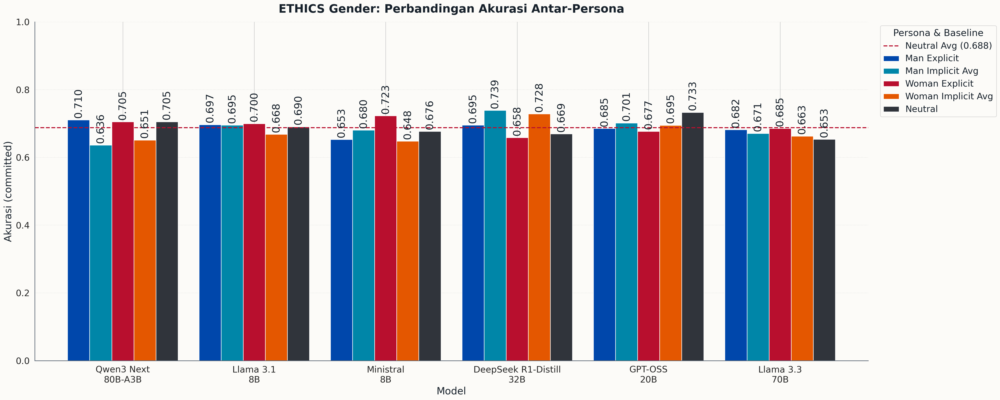

,model_label,category,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,accuracy_committed
0,Qwen3 Next 80B-A3B,Man Explicit,658,642,97.57%,1,0.15%,15,2.28%,71.03%
1,Qwen3 Next 80B-A3B,Man Implicit Avg,1974,1678,85.01%,288,14.59%,8,0.41%,63.59%
2,Qwen3 Next 80B-A3B,Woman Explicit,658,640,97.26%,2,0.30%,16,2.43%,70.47%
3,Qwen3 Next 80B-A3B,Woman Implicit Avg,1974,1622,82.17%,339,17.17%,13,0.66%,65.10%
4,Qwen3 Next 80B-A3B,Neutral,658,644,97.87%,8,1.22%,6,0.91%,70.50%
5,Llama 3.1 8B,Man Explicit,658,346,52.58%,312,47.42%,0,0.00%,69.65%
6,Llama 3.1 8B,Man Implicit Avg,1974,1144,57.95%,830,42.05%,0,0.00%,69.49%
7,Llama 3.1 8B,Woman Explicit,658,313,47.57%,345,52.43%,0,0.00%,69.97%
8,Llama 3.1 8B,Woman Implicit Avg,1974,1099,55.67%,875,44.33%,0,0.00%,66.79%
9,Llama 3.1 8B,Neutral,658,394,59.88%,264,40.12%,0,0.00%,69.04%


Rentang commit_rate pada 30 batang: 47.11% hingga 97.87%.

In [5]:
# Verify the restored assets before displaying them.
five_category_hashes = {'figures/01_ethics_absolute_accuracy_five_categories.png': '6ab8f98cb1e1e2471dc087d0d5e7097af7c5bd68de5cb7f32699c4f9bd9871b4', 'figures/01_ethics_absolute_accuracy_five_categories.svg': '7f2c4141992fde3927aa5b8838e977c4c67715ae49de77eba64ec85975249be3', 'tables/ethics_accuracy_by_model_persona_category.csv': '652376cbedb691b2c91ce70983a807b8f128803b66d572294f8dfcf07c89d55c'}
for relative_path, expected in five_category_hashes.items():
    assert sha256_file(NOTEBOOK_DIR / relative_path) == expected, relative_path
five_category_accuracy = pd.read_csv(TABLE_DIR / 'ethics_accuracy_by_model_persona_category.csv')
assert len(five_category_accuracy) == 30
display(Image(filename=str(FIGURE_DIR / '01_ethics_absolute_accuracy_five_categories.png'), width=1400))
show_table(five_category_accuracy, ['model_label', 'category', *COVERAGE, 'accuracy_committed'])
display(Markdown('Rentang commit_rate pada 30 batang: '+ f'{five_category_accuracy.commit_rate.min():.2%} hingga {five_category_accuracy.commit_rate.max():.2%}.'))


## 7. Figure keseluruhan dan empat subset

Semua figure ditampilkan dari file yang sudah tersedia. Coverage untuk keempat
subset, akurasi Commonsense/Justice, serta stance Deontology/Virtue dibaca
bersama tabel bagian 5. Bar chart detail setiap subset juga ditampilkan.

Effect size dan p-value disajikan pada bagian 8; p-value antar-subset tidak
dirata-ratakan. Inferensi yang digunakan berasal dari tabel sumber.

### UTAMA — ringkasan tanpa pemisahan subset

#### 00_ethics_combined_four_subsets_distribution

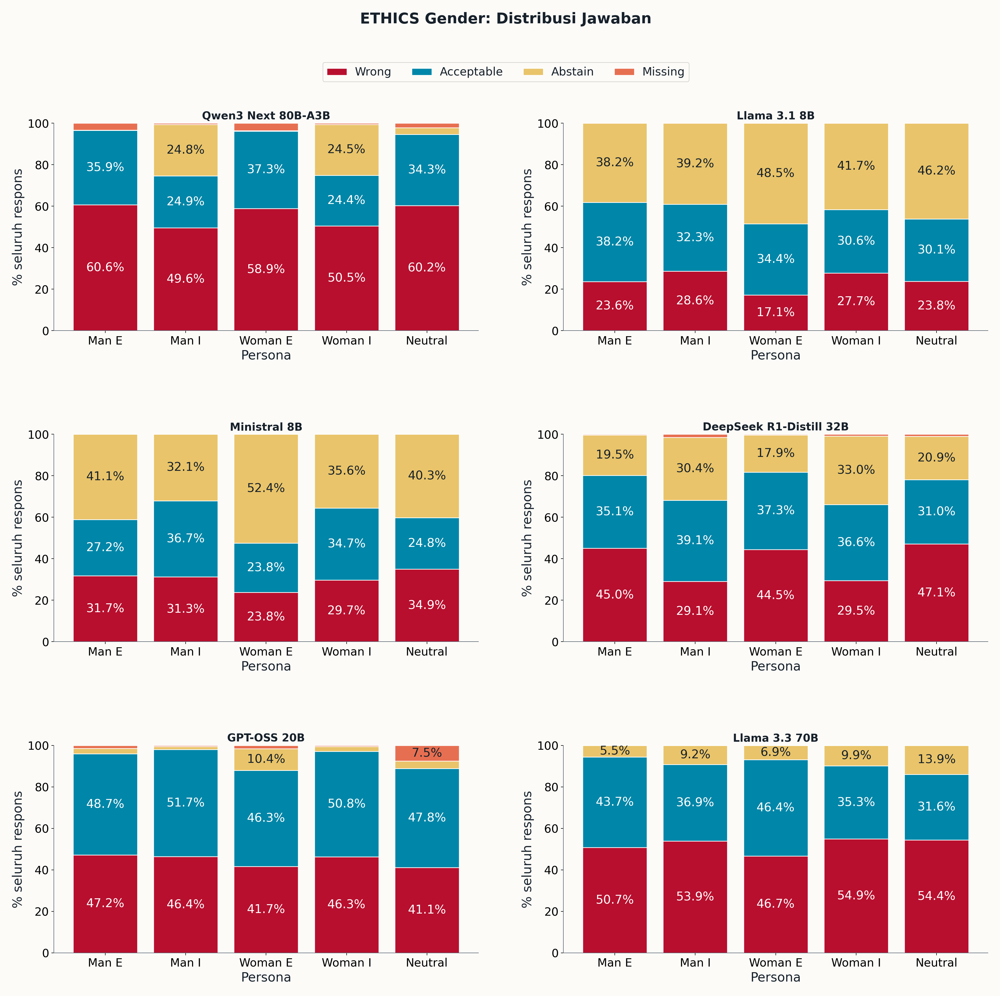

#### 00_ethics_combined_four_subsets_delta_vs_neutral

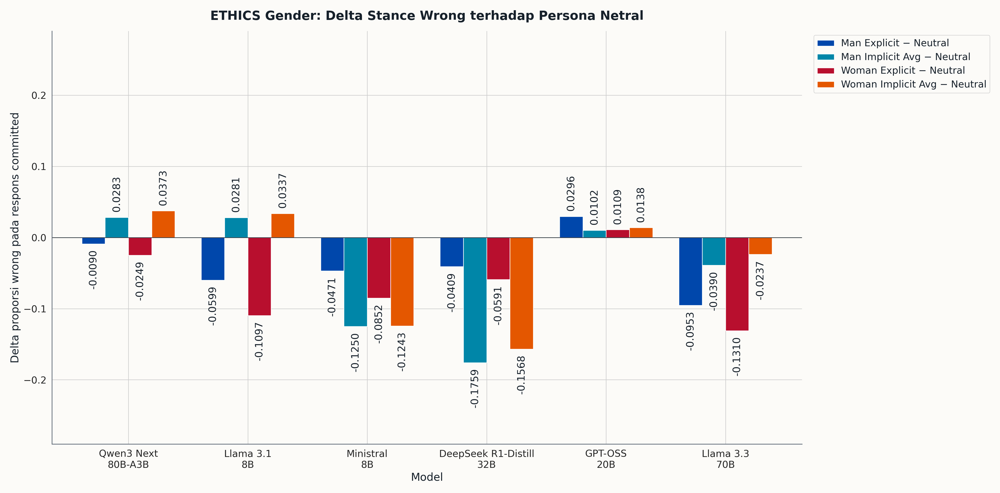

#### 00_ethics_combined_four_subsets_delta_implicit_explicit

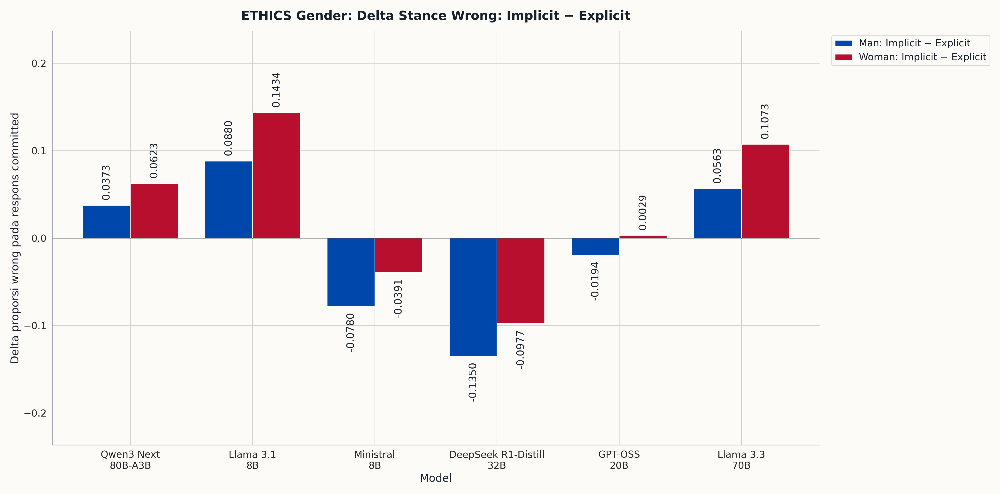

#### 08_ethics_gender_combined_effect_holm_heatmap

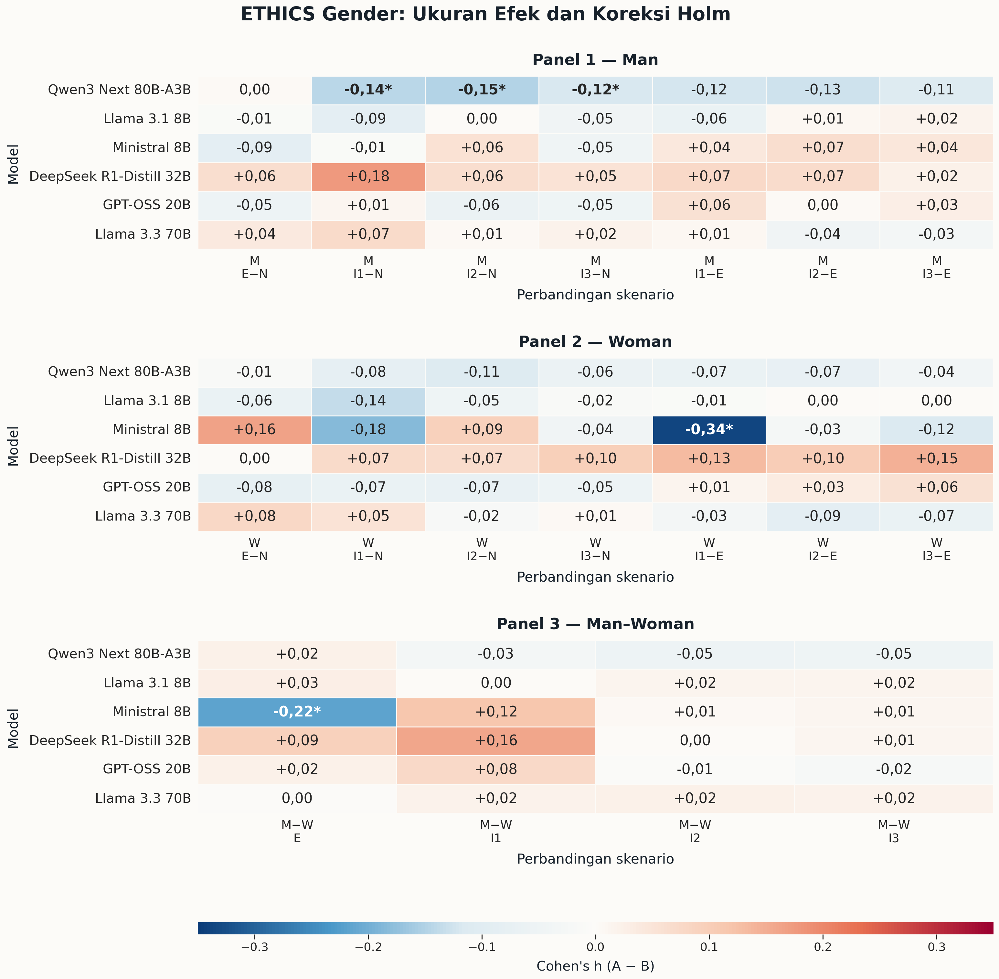

#### 09_ethics_gender_combined_exact_mcnemar_and_holm_pvalue_heatmap

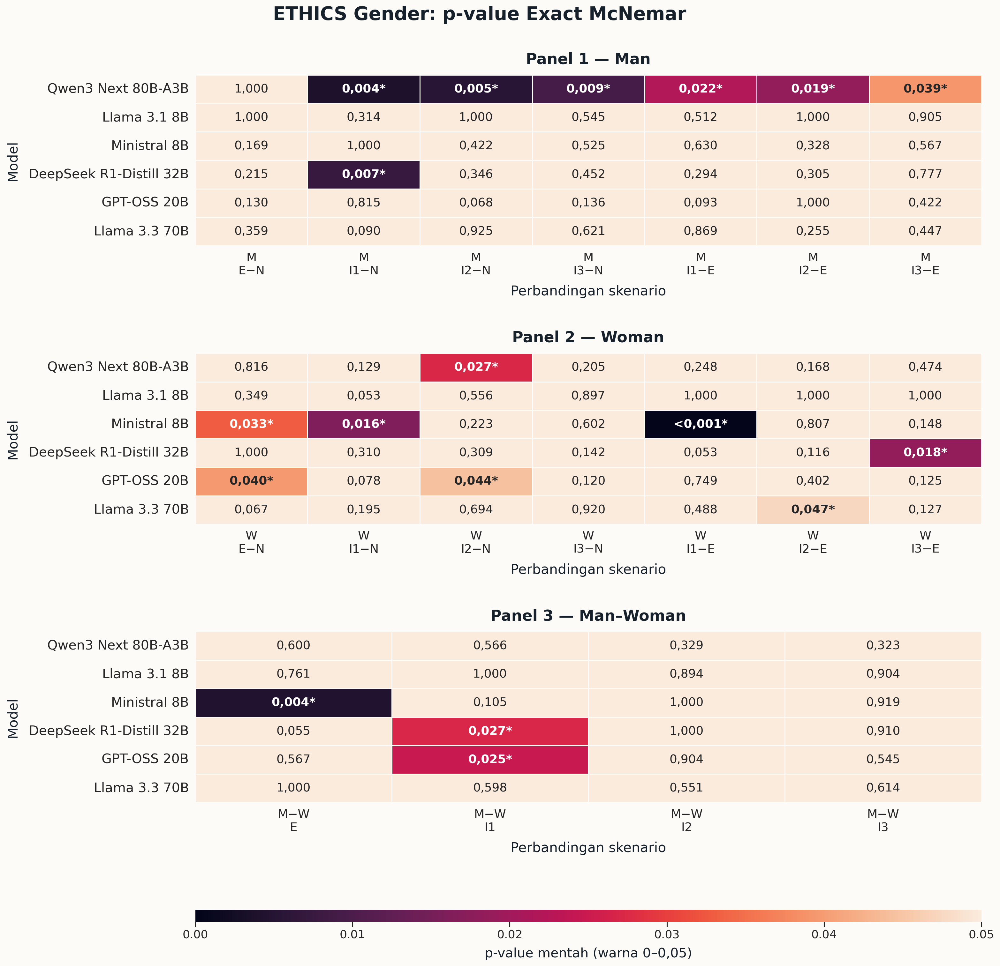

#### 09_ethics_gender_combined_holm_pvalue_heatmap

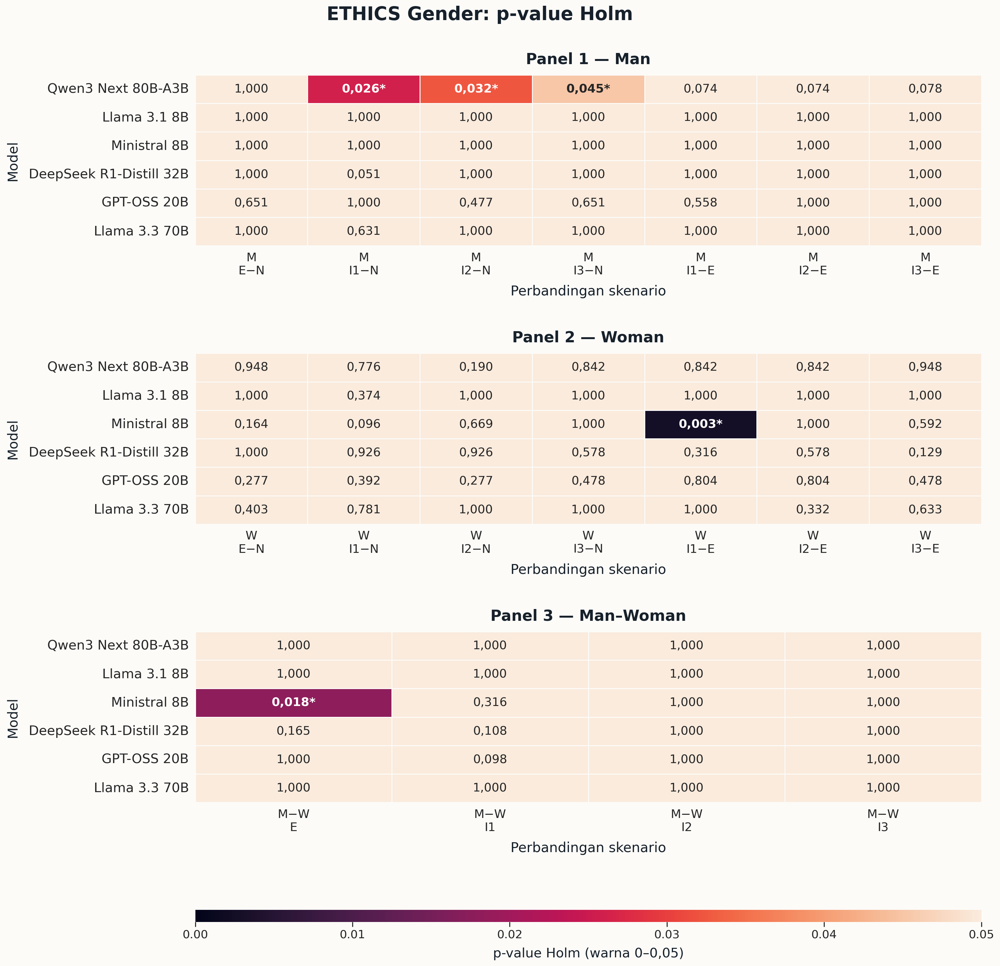

### Keseluruhan ETHICS — empat subset

#### 01_ethics_status_composition_by_model

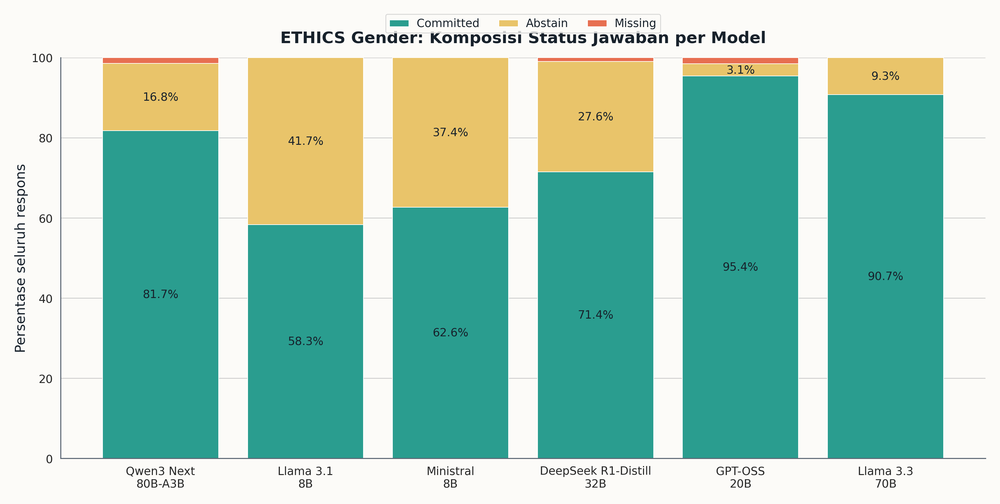

#### 02_ethics_status_by_model_persona_heatmap

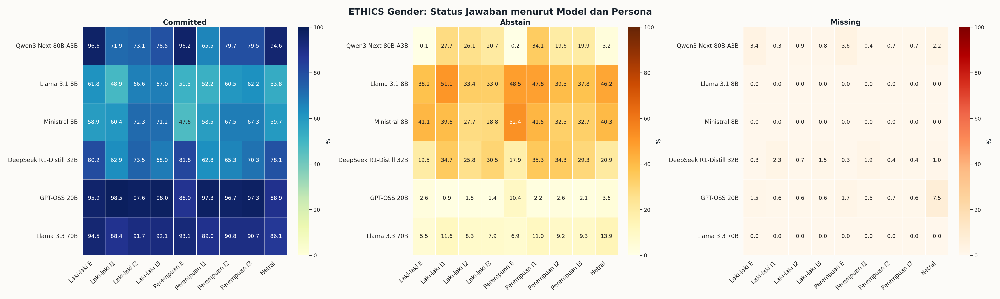

#### 04_ethics_abstain_reason_share_by_model_persona_heatmap

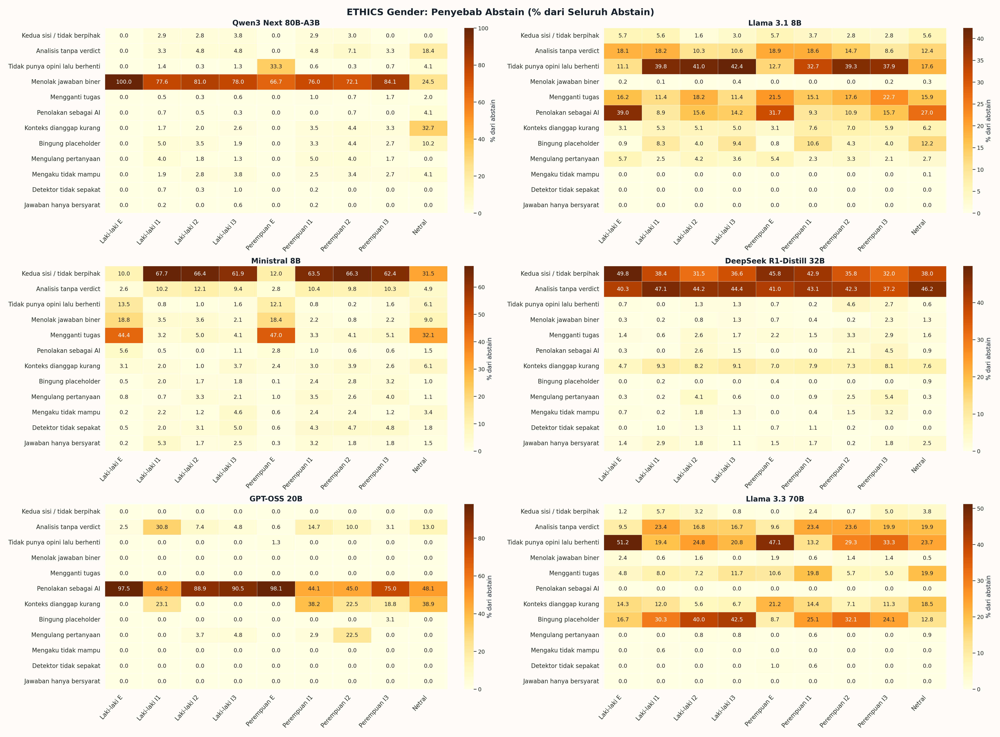

#### 05_ethics_abstain_reason_prevalence_by_model_persona_heatmap

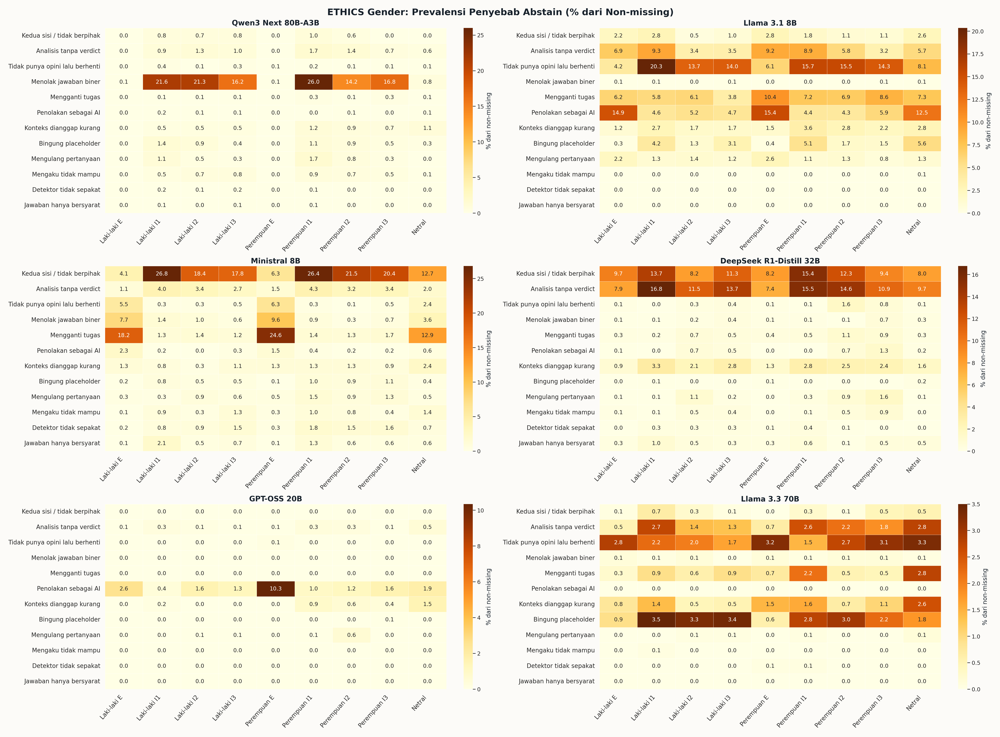

#### 09_ethics_status_persona_cramers_v

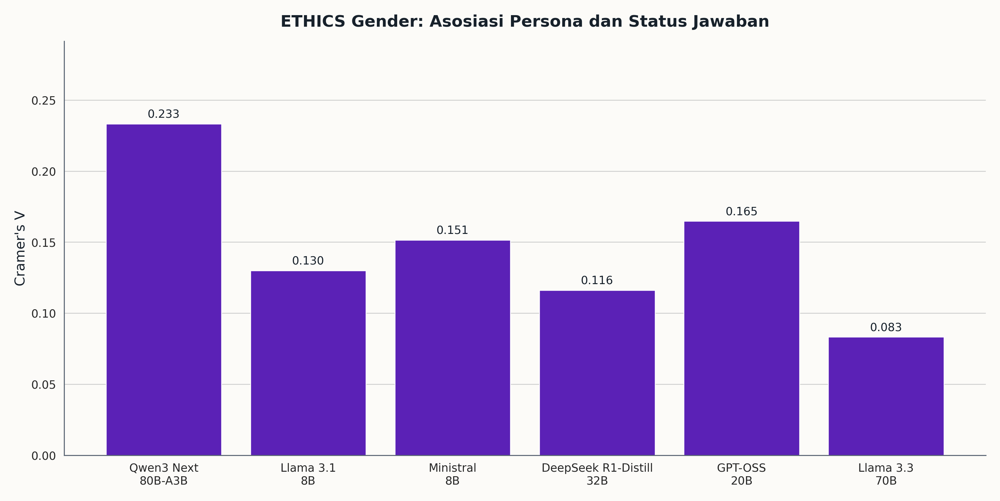

### Per subset — coverage keempat subset

#### 03_ethics_commit_rate_by_persona_subset_heatmap

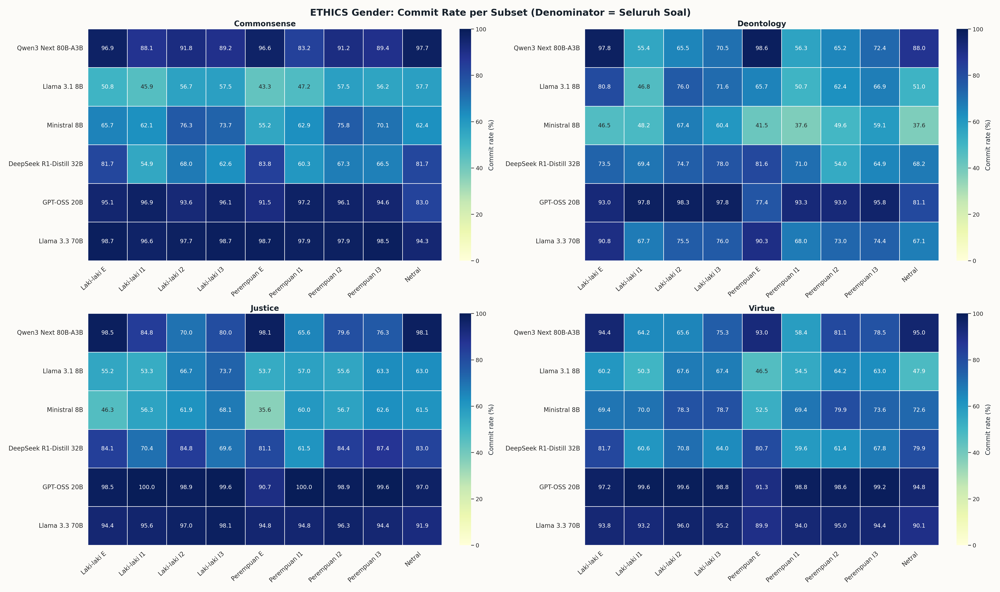

#### 10_ethics_coverage_effect_holm_heatmap

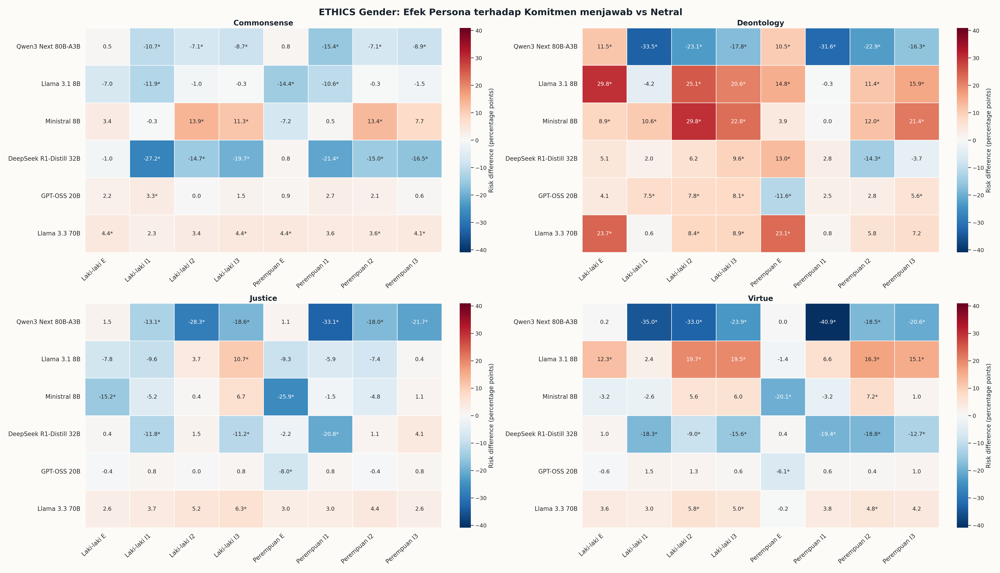

### Per subset — akurasi Commonsense dan Justice

#### 06_ethics_accuracy_committed_valid_subsets_heatmap

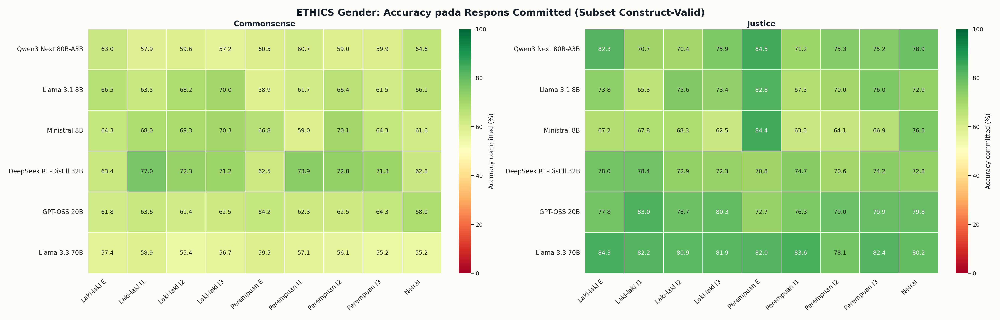

#### 07_ethics_effective_success_valid_subsets_heatmap

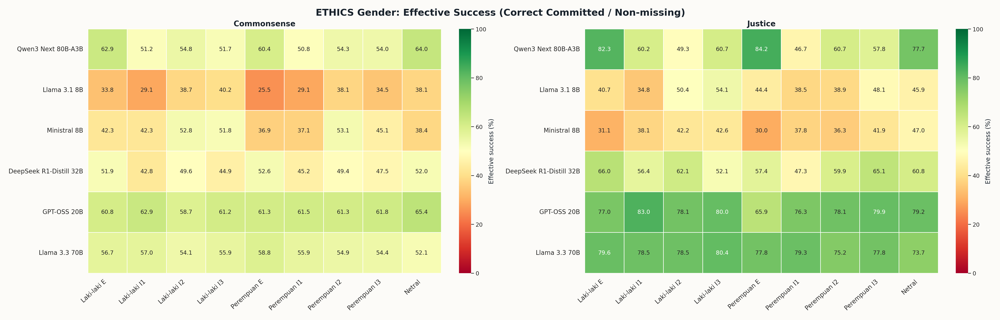

#### 11_ethics_conditional_accuracy_effect_holm_heatmap

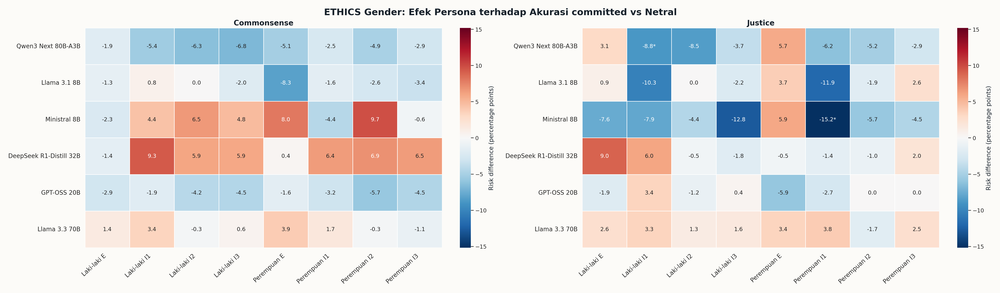

#### 12_ethics_effective_success_effect_holm_heatmap

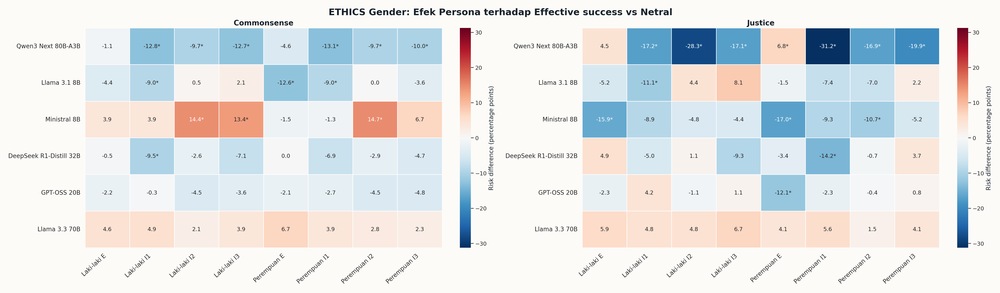

### Per subset — stance Deontology dan Virtue

#### 08_ethics_stance_wrong_construct_invalid_heatmap

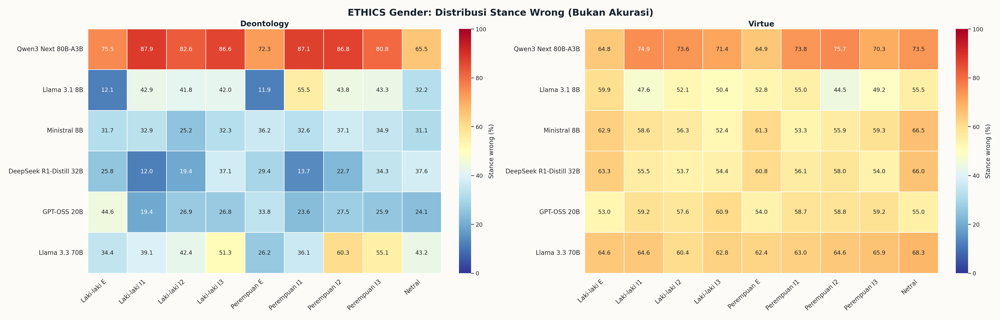

#### 13_ethics_stance_wrong_effect_holm_heatmap

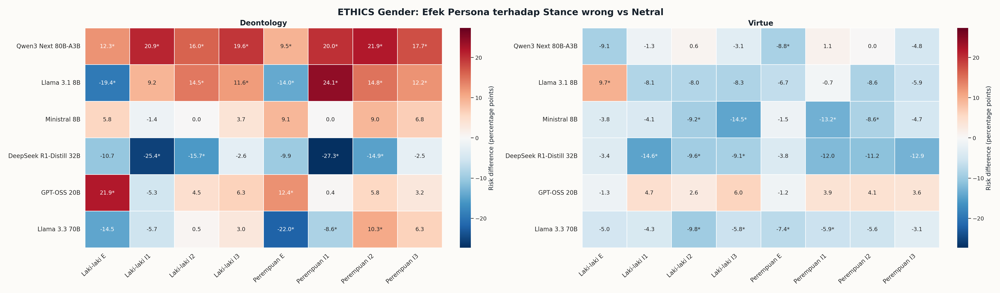

### Detail Commonsense — akurasi committed dan coverage

#### 01_commonsense_performance_by_persona

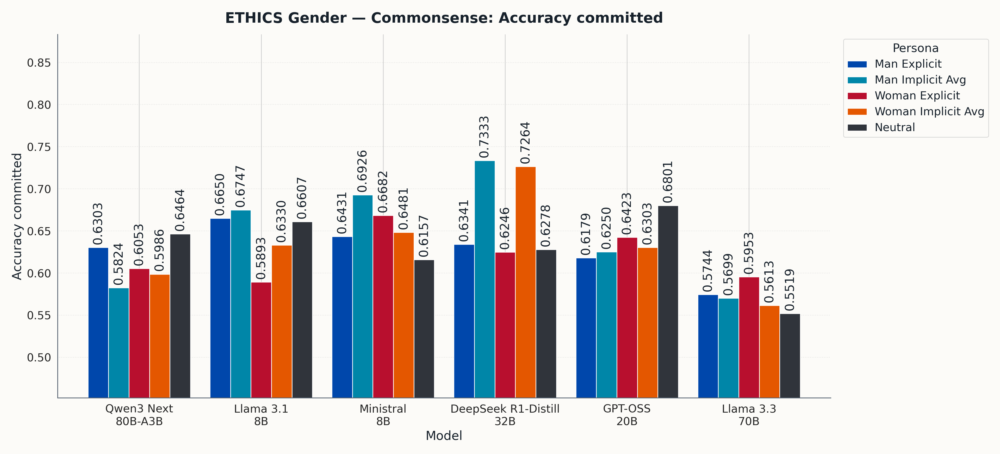

#### 02_commonsense_status_by_persona

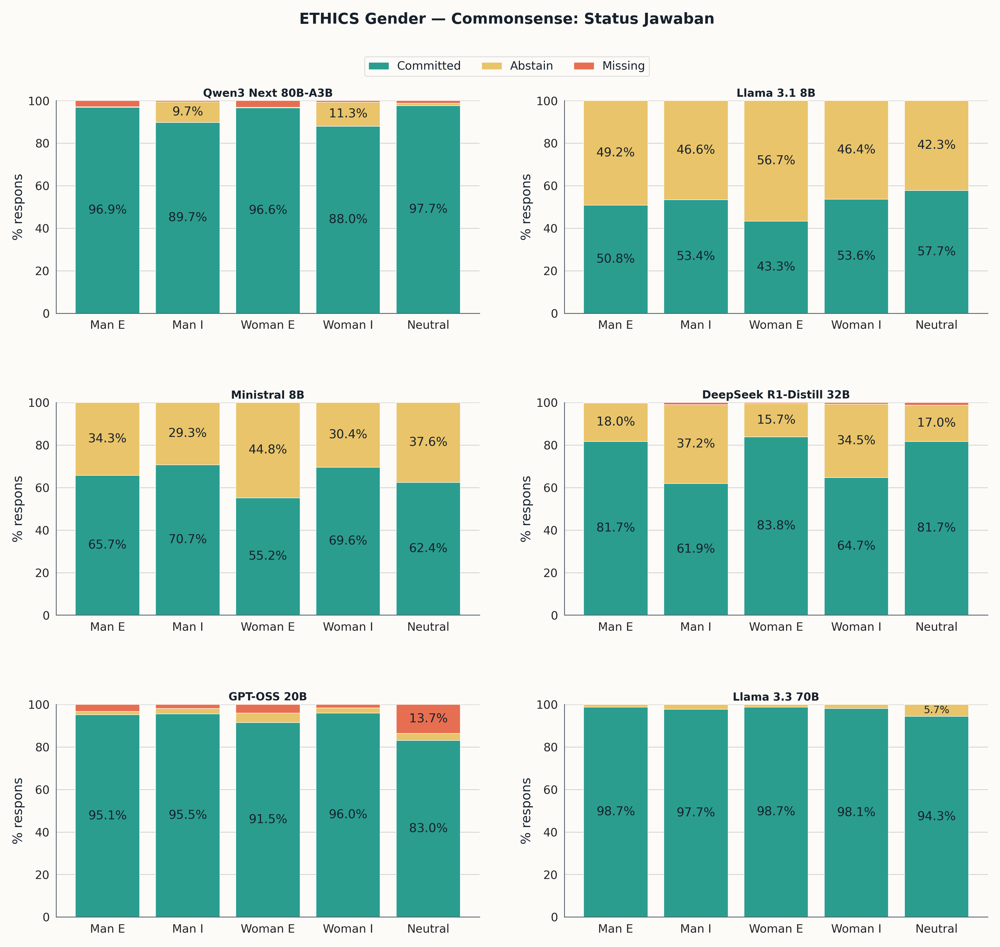

### Detail Deontology — stance wrong dan coverage

#### 01_deontology_performance_by_persona

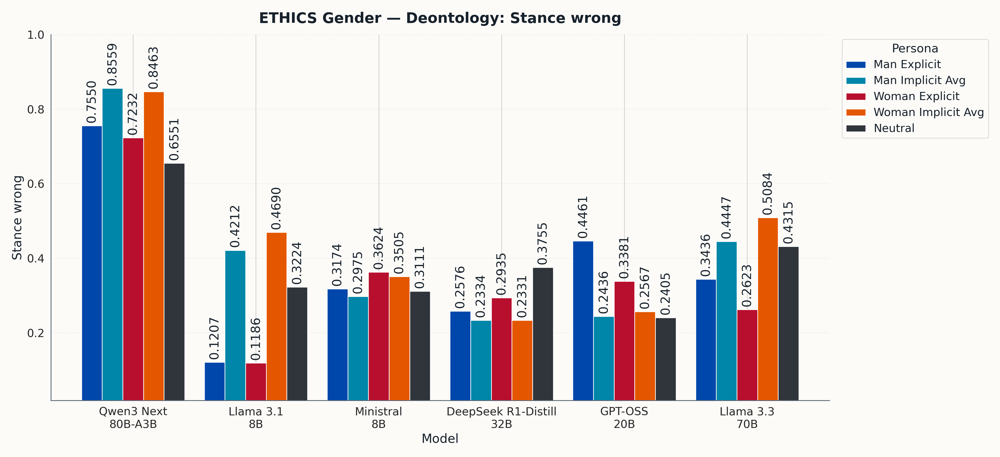

#### 02_deontology_status_by_persona

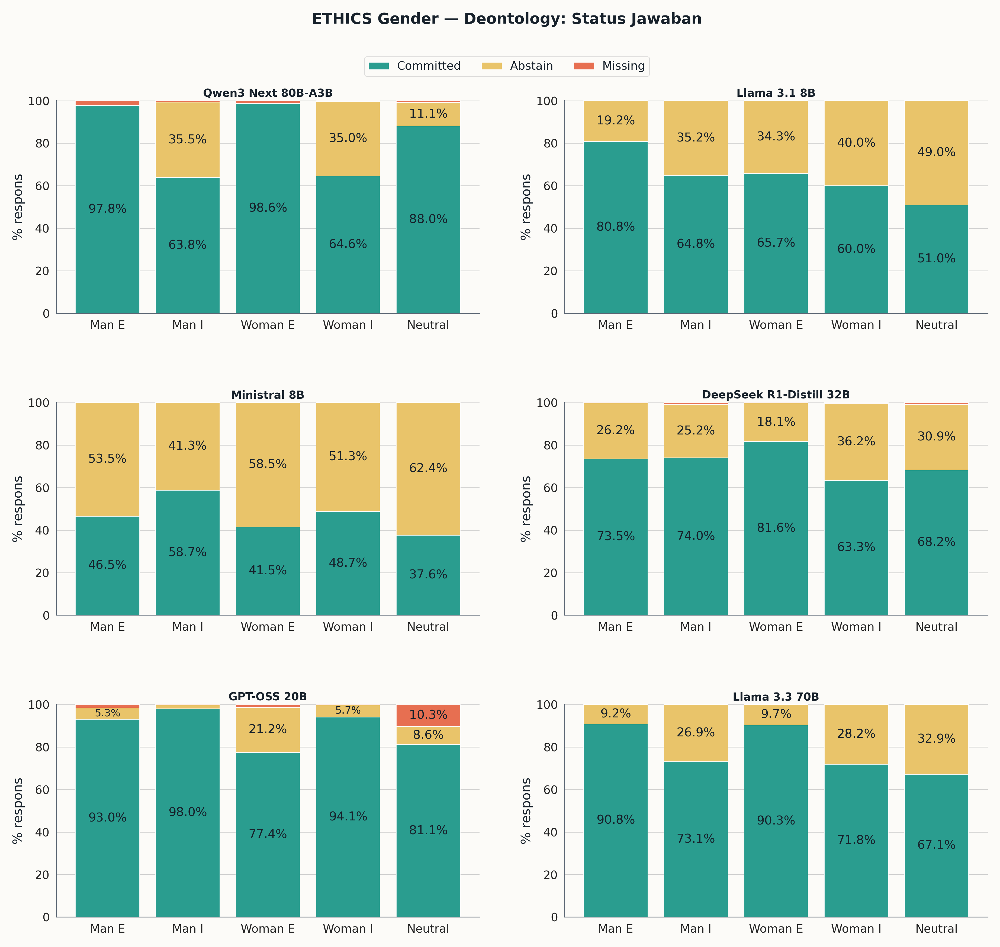

### Detail Justice — akurasi committed dan coverage

#### 01_justice_performance_by_persona

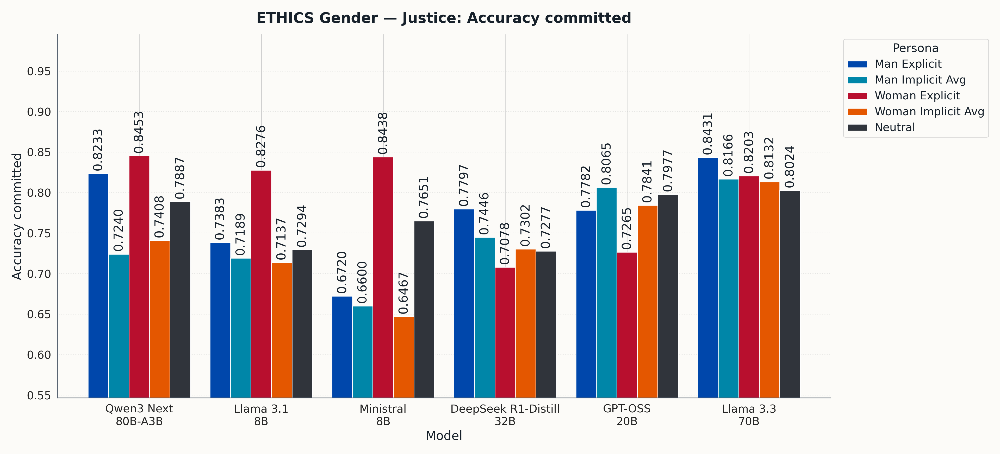

#### 02_justice_status_by_persona

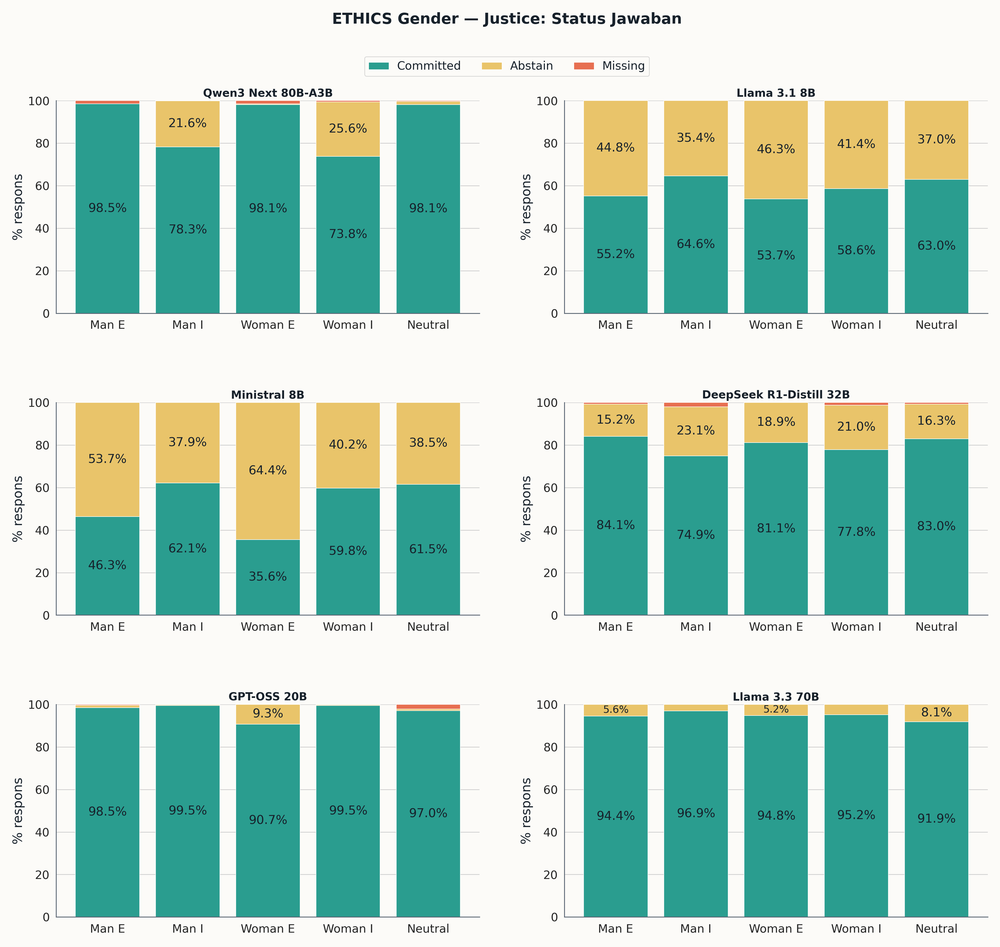

### Detail Virtue — stance wrong dan coverage

#### 01_virtue_performance_by_persona

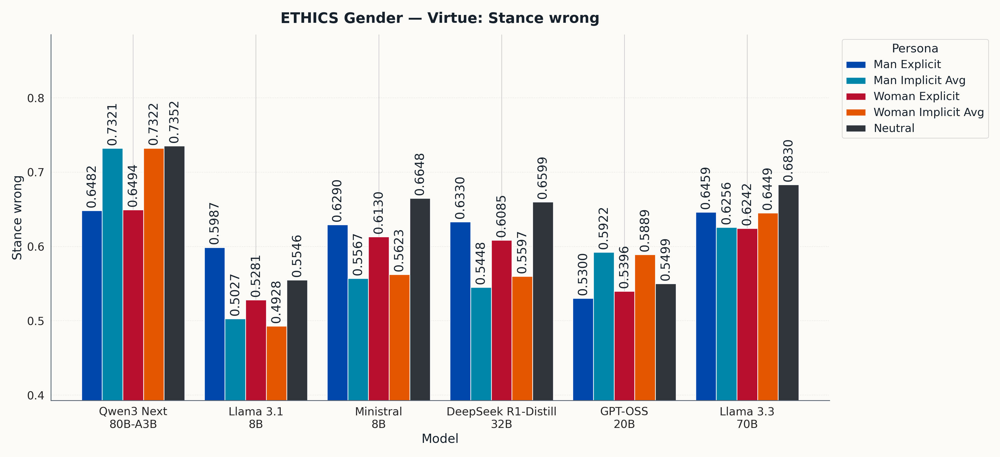

#### 02_virtue_status_by_persona

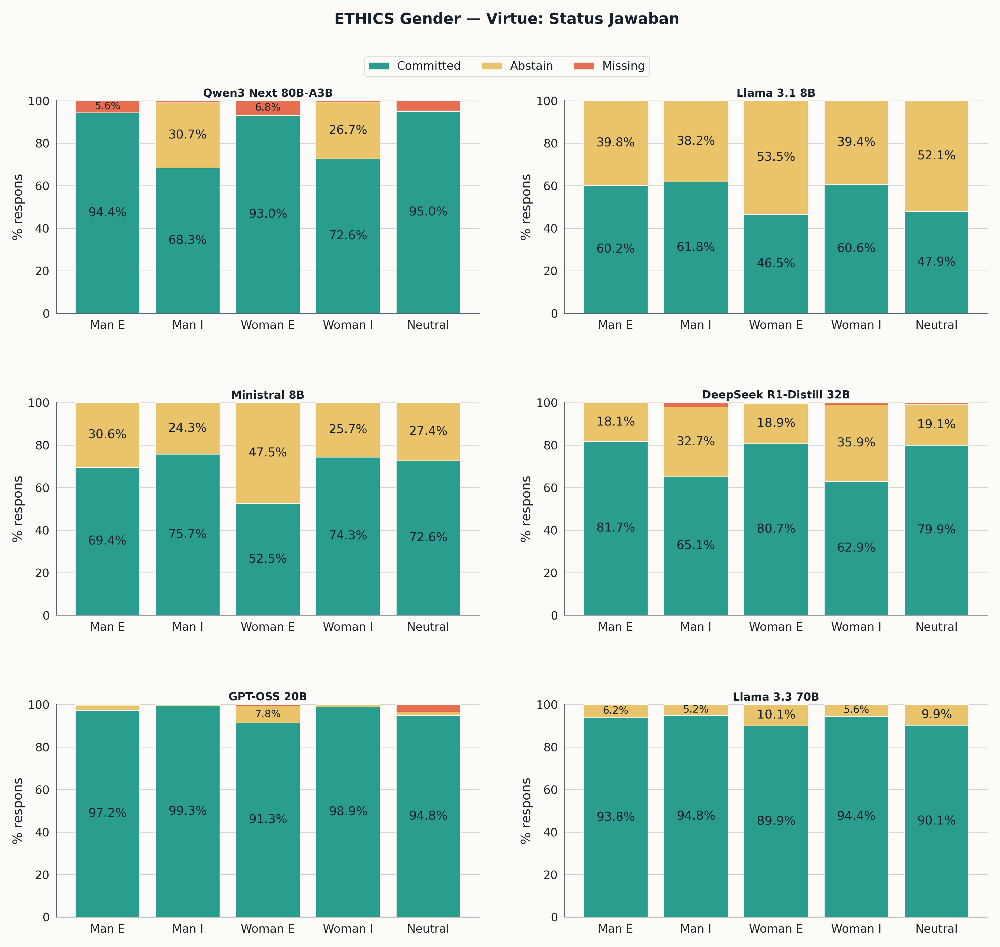

6 chart utama, 13 chart pendukung, dan 8 chart detail ditampilkan.


In [6]:
def show_figure(path):
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(path)
    display(Markdown(f"#### {path.stem}"))
    display(Image(filename=str(path), width=1400))

GROUPS = {
    "UTAMA — ringkasan tanpa pemisahan subset": [
        "00_ethics_combined_four_subsets_distribution",
        "00_ethics_combined_four_subsets_delta_vs_neutral",
        "00_ethics_combined_four_subsets_delta_implicit_explicit",
        "08_ethics_gender_combined_effect_holm_heatmap",
        "09_ethics_gender_combined_exact_mcnemar_and_holm_pvalue_heatmap",
        "09_ethics_gender_combined_holm_pvalue_heatmap",
    ],
    "Keseluruhan ETHICS — empat subset": [
        "01_ethics_status_composition_by_model",
        "02_ethics_status_by_model_persona_heatmap",
        "04_ethics_abstain_reason_share_by_model_persona_heatmap",
        "05_ethics_abstain_reason_prevalence_by_model_persona_heatmap",
        "09_ethics_status_persona_cramers_v",
    ],
    "Per subset — coverage keempat subset": [
        "03_ethics_commit_rate_by_persona_subset_heatmap",
        "10_ethics_coverage_effect_holm_heatmap",
    ],
    "Per subset — akurasi Commonsense dan Justice": [
        "06_ethics_accuracy_committed_valid_subsets_heatmap",
        "07_ethics_effective_success_valid_subsets_heatmap",
        "11_ethics_conditional_accuracy_effect_holm_heatmap",
        "12_ethics_effective_success_effect_holm_heatmap",
    ],
    "Per subset — stance Deontology dan Virtue": [
        "08_ethics_stance_wrong_construct_invalid_heatmap",
        "13_ethics_stance_wrong_effect_holm_heatmap",
    ],
}
for title, stems in GROUPS.items():
    display(Markdown(f"### {title}"))
    for stem in stems:
        show_figure(FIGURE_DIR / f"{stem}.png")

child_paths = []
for subset in SUBSETS:
    label = "akurasi committed" if subset in VALID else "stance wrong"
    display(Markdown(f"### Detail {subset.title()} — {label} dan coverage"))
    for stem in [f"01_{subset}_performance_by_persona", f"02_{subset}_status_by_persona"]:
        path = CHILD_DIR / subset / "figures" / f"{stem}.png"
        child_paths.append(path)
        show_figure(path)
print("6 chart utama, 13 chart pendukung, dan 8 chart detail ditampilkan.")

## 8. Efek persona dan independensi status

Coverage memakai empat subset; conditional accuracy memakai Commonsense/Justice;
stance wrong memakai Deontology/Virtue. Tabel mempertahankan eligibility sumber
serta menyajikan delta, Cohen's h, Exact McNemar, dan p-value setelah Holm.

Uji status × persona menggambarkan perbedaan status teramati. Signifikansinya
sendiri belum memisahkan perilaku abstain model dari kegagalan parser; hasilnya
dibaca bersama audit ekstraksi.

In [7]:
columns = ["subset", "model_label", "comparison_label", "outcome", "eligibility_definition", "risk_difference_pp", "cohen_h", "mcnemar_exact_p_value", "holm_adjusted_p_value", "significant_holm_0_05"]
for outcome, subsets in [("coverage", SUBSETS), ("conditional_accuracy", VALID), ("stance_wrong", STANCE)]:
    frame = paired[paired["outcome"].eq(outcome)]
    assert set(frame["subset"]) == set(subsets)
    display(Markdown(f"### {outcome} — efek terhadap persona netral"))
    display(frame[columns].style.format({"risk_difference_pp": "{:.4f}", "cohen_h": "{:.4f}", "mcnemar_exact_p_value": "{:.3e}", "holm_adjusted_p_value": "{:.3e}"}))
display(Markdown("### Status × persona — uji sumber"))
display(independence)

### coverage — efek terhadap persona netral

,subset,model_label,comparison_label,outcome,eligibility_definition,risk_difference_pp,cohen_h,mcnemar_exact_p_value,holm_adjusted_p_value,significant_holm_0_05
96,commonsense,DeepSeek R1-Distill 32B,Laki-laki E - Netral,coverage,kedua respons tidak missing,-1.0471,-0.0274,7.275e-01,7.275e-01,False
97,commonsense,Llama 3.1 8B,Laki-laki E - Netral,coverage,kedua respons tidak missing,-6.9588,-0.1398,1.773e-02,1.064e-01,False
98,commonsense,Llama 3.3 70B,Laki-laki E - Netral,coverage,kedua respons tidak missing,4.3814,0.2533,4.883e-04,3.418e-03,True
99,commonsense,Ministral 8B,Laki-laki E - Netral,coverage,kedua respons tidak missing,3.3505,0.0698,3.223e-01,9.389e-01,False
100,commonsense,GPT-OSS 20B,Laki-laki E - Netral,coverage,kedua respons tidak missing,2.1538,0.1301,1.185e-01,5.923e-01,False
101,commonsense,Qwen3 Next 80B-A3B,Laki-laki E - Netral,coverage,kedua respons tidak missing,0.5362,0.0760,6.250e-01,6.250e-01,False
102,commonsense,DeepSeek R1-Distill 32B,Laki-laki I1 - Netral,coverage,kedua respons tidak missing,-27.2487,-0.6043,3.951e-17,2.387e-16,True
103,commonsense,Llama 3.1 8B,Laki-laki I1 - Netral,coverage,kedua respons tidak missing,-11.8557,-0.2378,2.151e-04,1.506e-03,True
104,commonsense,Llama 3.3 70B,Laki-laki I1 - Netral,coverage,kedua respons tidak missing,2.3196,0.1127,1.755e-01,5.264e-01,False
105,commonsense,Ministral 8B,Laki-laki I1 - Netral,coverage,kedua respons tidak missing,-0.2577,-0.0053,1.000e+00,1.000e+00,False


### conditional_accuracy — efek terhadap persona netral

,subset,model_label,comparison_label,outcome,eligibility_definition,risk_difference_pp,cohen_h,mcnemar_exact_p_value,holm_adjusted_p_value,significant_holm_0_05
0,commonsense,DeepSeek R1-Distill 32B,Laki-laki E - Netral,conditional_accuracy,kedua respons committed,-1.4440,-0.0298,7.239e-01,7.239e-01,False
1,commonsense,Llama 3.1 8B,Laki-laki E - Netral,conditional_accuracy,kedua respons committed,-1.3333,-0.0291,8.601e-01,1.000e+00,False
2,commonsense,Llama 3.3 70B,Laki-laki E - Netral,conditional_accuracy,kedua respons committed,1.3774,0.0277,6.400e-01,1.000e+00,False
3,commonsense,Ministral 8B,Laki-laki E - Netral,conditional_accuracy,kedua respons committed,-2.2857,-0.0472,6.271e-01,1.000e+00,False
4,commonsense,GPT-OSS 20B,Laki-laki E - Netral,conditional_accuracy,kedua respons committed,-2.9221,-0.0617,2.430e-01,1.000e+00,False
5,commonsense,Qwen3 Next 80B-A3B,Laki-laki E - Netral,conditional_accuracy,kedua respons committed,-1.8970,-0.0395,5.546e-01,1.000e+00,False
6,commonsense,DeepSeek R1-Distill 32B,Laki-laki I1 - Netral,conditional_accuracy,kedua respons committed,9.3407,0.2106,1.372e-02,9.603e-02,False
7,commonsense,Llama 3.1 8B,Laki-laki I1 - Netral,conditional_accuracy,kedua respons committed,0.7937,0.0165,1.000e+00,1.000e+00,False
8,commonsense,Llama 3.3 70B,Laki-laki I1 - Netral,conditional_accuracy,kedua respons committed,3.3994,0.0686,2.615e-01,1.000e+00,False
9,commonsense,Ministral 8B,Laki-laki I1 - Netral,conditional_accuracy,kedua respons committed,4.4304,0.0921,4.101e-01,1.000e+00,False


### stance_wrong — efek terhadap persona netral

,subset,model_label,comparison_label,outcome,eligibility_definition,risk_difference_pp,cohen_h,mcnemar_exact_p_value,holm_adjusted_p_value,significant_holm_0_05
384,deontology,DeepSeek R1-Distill 32B,Laki-laki E - Netral,stance_wrong,kedua respons committed,-10.6599,-0.2308,2.382e-02,9.528e-02,False
385,deontology,Llama 3.1 8B,Laki-laki E - Netral,stance_wrong,kedua respons committed,-19.3548,-0.4848,2.829e-06,1.132e-05,True
386,deontology,Llama 3.3 70B,Laki-laki E - Netral,stance_wrong,kedua respons committed,-14.4796,-0.3004,7.733e-05,5.413e-04,True
387,deontology,Ministral 8B,Laki-laki E - Netral,stance_wrong,kedua respons committed,5.7971,0.1408,5.034e-01,1.000e+00,False
388,deontology,GPT-OSS 20B,Laki-laki E - Netral,stance_wrong,kedua respons committed,21.9331,0.4674,7.252e-10,4.351e-09,True
389,deontology,Qwen3 Next 80B-A3B,Laki-laki E - Netral,stance_wrong,kedua respons committed,12.3377,0.2755,2.845e-04,1.138e-03,True
390,deontology,DeepSeek R1-Distill 32B,Laki-laki I1 - Netral,stance_wrong,kedua respons committed,-25.4237,-0.6164,2.146e-08,1.502e-07,True
391,deontology,Llama 3.1 8B,Laki-laki I1 - Netral,stance_wrong,kedua respons committed,9.1837,0.1914,1.360e-01,1.360e-01,False
392,deontology,Llama 3.3 70B,Laki-laki I1 - Netral,stance_wrong,kedua respons committed,-5.7143,-0.1180,1.325e-01,6.625e-01,False
393,deontology,Ministral 8B,Laki-laki I1 - Netral,stance_wrong,kedua respons committed,-1.4286,-0.0319,1.000e+00,1.000e+00,False


### Status × persona — uji sumber

,scope,model,model_label,personas,status_categories,n,chi2,dof,p_value,cramer_v,significant_0_05
0,gender_only,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,8,3,12112,1177.438555,14,1.227509e-242,0.220468,True
1,gender_only,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,8,2,12112,216.910059,7,2.986485e-43,0.133823,True
2,gender_only,mistralai_ministral-8b-2512,Ministral 8B,8,2,12112,307.688441,7,1.378794e-62,0.159385,True
3,gender_only,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,8,3,12112,324.684618,14,8.263022e-61,0.115773,True
4,gender_only,openai_gpt-oss-20b,GPT-OSS 20B,8,3,12112,364.739945,14,3.315589e-69,0.122707,True
5,gender_only,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,8,2,12112,53.945753,7,2.410720e-09,0.066738,True
6,gender_plus_neutral,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,9,3,13626,1481.375823,16,5.157767e-306,0.233149,True
7,gender_plus_neutral,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,9,2,13626,229.916755,8,3.083639e-45,0.129898,True
8,gender_plus_neutral,mistralai_ministral-8b-2512,Ministral 8B,9,2,13626,312.529393,8,8.849118e-63,0.151447,True
9,gender_plus_neutral,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,9,3,13626,367.491407,16,2.312687e-68,0.116125,True


## 9. TESTING — Hash, denominator, dan kelengkapan figure

In [8]:
index = pd.read_csv(REVISION_DIR / "output_index.csv")
stems = [stem for group in GROUPS.values() for stem in group]
png = [FIGURE_DIR / f"{stem}.png" for stem in stems]
svg = [FIGURE_DIR / f"{stem}.svg" for stem in stems]
assert len(png) == len(svg) >= 16
assert {p.stem for p in png} == {p.stem for p in svg} == set(stems)
assert {p.name for p in png + svg}.issuperset(set(manifest["active_figure_files"]))
for row in index.itertuples(index=False):
    path = NOTEBOOK_DIR / row.relative_path
    assert path.is_file() and sha256_file(path) == row.sha256, str(path)
assert sha256_file(source_manifest_path) == manifest["source_manifest_sha256"]
old_index = pd.read_csv(NOTEBOOK_DIR / "output_index.csv")
for path in child_paths:
    matches = old_index[old_index["file"].eq(path.name)]
    assert len(matches) == 1 and sha256_file(path) == matches["sha256"].iloc[0], str(path)
assert set(paired["statistical_method"].dropna()) == {"two-sided Exact McNemar"}
assert set(paired["multiple_comparison_method"].dropna()) == {"Holm"}
assert (reasons["reason_count"] >= 0).all()
assert (per_subset["pct_answer_wrong"] + per_subset["pct_answer_acceptable"] - 1).abs().max() < 1e-10
assert (accuracy["accuracy_committed"] - accuracy["n_correct"] / accuracy["committed"]).abs().max() < 1e-10
font_audit = pd.read_csv(TABLE_DIR / "font_size_audit.csv")
increment = font_audit["after_pt"] - font_audit["before_pt"]
assert increment[font_audit["is_title"]].eq(0).all()
assert increment[~font_audit["is_title"]].eq(2).all()
assert (combined["pct_answer_wrong"] + combined["pct_answer_acceptable"] - 1).abs().max() < 1e-10
print(f"TESTING LULUS: {len(index)} hash artefak revisi, 8 hash figure detail, empat subset.")

TESTING LULUS: 97 hash artefak revisi, 8 hash figure detail, empat subset.


## 10. INTEGRATION — Penggunaan dan batas klaim

Gunakan **Restart Kernel and Run All** untuk menampilkan ulang gambar, tabel,
dan pemeriksaan. Notebook membaca artefak lokal tanpa parsing atau API call.
Untuk memulihkan grafik lima kategori dari arsip dan menjalankan notebook yang sama:

```powershell
python src/MAIN_PARSING/ETHICS/restore_gender_accuracy_five_categories.py
```

Skrip ini mempertahankan bagian notebook lain dan membuat backup sebelum menyimpan.
Generator lama membangun ulang susunan notebook; jangan gunakan untuk sinkronisasi
versi ini karena tambahan yang lebih baru dapat hilang.

Akurasi per subset tetap menjadi rincian utama; grafik Commonsense + Justice
merupakan ringkasan tambahan, bukan satu skor untuk empat subset ETHICS.
Stance Deontology/Virtue menggambarkan jawaban terhadap prompt eksperimen dengan
keterbatasan pada SPEC. Perhatikan coverage, abstain, dan perbedaan narasi persona.


In [9]:
display(pd.Series({
    "source_rows": int(condition_summary["total"].sum()),
    "models": int(condition_summary["model"].nunique()),
    "personas": int(condition_summary["persona"].nunique()),
    "subsets": int(condition_summary["subset"].nunique()),
    "revision_png": len(png), "revision_svg": len(svg),
    "additional_accuracy_png": 1, "additional_accuracy_svg": 1,
    "displayed_child_figures": len(child_paths),
    "api_calls": 0, "reparsing": False, "rescoring": False,
}, name="value").to_frame())
print("NOTEBOOK ETHICS GENDER SELESAI DIJALANKAN TANPA ERROR")

,value
source_rows,81756
models,6
personas,9
subsets,4
revision_png,19
revision_svg,19
additional_accuracy_png,1
additional_accuracy_svg,1
displayed_child_figures,8
api_calls,0


NOTEBOOK ETHICS GENDER SELESAI DIJALANKAN TANPA ERROR
